# Avance 3 — Capítulo 9: Validación temporal, umbrales y pronósticos

**Por:**
* Diego de Jesús Muñoz González
* Alexander Góngora Venegas

**Activo:** BTC-USD · **Frecuencia:** diaria · **Objetivo:** rendimiento del siguiente día, y<sub>t</sub> = P<sub>t+1</sub> / P<sub>t</sub> − 1 · **Entorno:** Google Colab con GPU NVIDIA T4.

Este notebook continúa los Avances 1 y 2 (mismo activo, ventana de 20 rendimientos, variable `ret` y particiones TR–VA–TE). Comprueba si los resultados se sostienen a lo largo del tiempo y define una regla de señal con umbral.

**Entregables (según el protocolo):**
1. Tres evaluaciones con ventana expansiva dentro de TR y el error de cada ventana. Cada entrenamiento termina antes del bloque que evalúa y las transformaciones se reajustan solo con ese entrenamiento.
2. Pronóstico de un periodo (trabajo obligatorio). La ampliación opcional de varios periodos (directo vs. recursivo) no se realiza.
3. Hasta cinco umbrales candidatos, uno elegido en VA: comprar cuando el rendimiento estimado supera δ; en otro caso, permanecer en efectivo.
4. Explicación de la diferenciación fraccionaria (su implementación es opcional y no se hace).

**Reglas que se respetan:** VA se usa para la selección final y TE permanece reservado: no se carga, no se transforma y no interviene en ninguna decisión.

## 1. Preparar el entorno

In [1]:
import os, sys, json, time, random, subprocess, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


## 2. Verificar la GPU NVIDIA T4 (requisito obligatorio)
Si no hay T4 o TensorFlow no la usa, **se detiene el entrenamiento profundo** y se registra el incidente.

In [2]:
try:
    smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True)
    print(smi.stdout)
except (subprocess.SubprocessError, OSError) as e:
    raise RuntimeError("No se pudo ejecutar nvidia-smi. Activa una GPU T4 en Google Colab (Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU) y registra el incidente.") from e

gpus = tf.config.list_physical_devices("GPU")
print("GPUs reconocidas por TensorFlow:", gpus)
if not gpus:
    raise RuntimeError("TensorFlow no reconoce ninguna GPU. Detén el avance, configura Colab con T4 y registra el incidente.")

gpu_names = []
for g in gpus:
    try:
        gpu_names.append(str(tf.config.experimental.get_device_details(g).get("device_name", "")))
    except (ValueError, RuntimeError, AttributeError):
        gpu_names.append("")
print("Nombre(s) reportado(s) por TensorFlow:", gpu_names)

if "t4" not in smi.stdout.lower() and not any("t4" in n.lower() for n in gpu_names):
    raise RuntimeError("La GPU detectada no se identifica como NVIDIA T4. No se iniciará el entrenamiento.")

tf.config.set_soft_device_placement(False)
with tf.device("/GPU:0"):
    prueba_gpu = tf.matmul(tf.random.normal((512, 512)), tf.random.normal((512, 512)))
print("Dispositivo de la operación de prueba:", prueba_gpu.device)
assert "GPU:0" in prueba_gpu.device.upper(), "La operación de prueba no se ejecutó en GPU."
print("✔ GPU NVIDIA T4 detectada y operación verificada.")

Thu Nov 12 04:27:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Localizar los archivos
La carpeta del avance (con `dlfin/`, `datos/`, `salidas/` y `salidas_capitulo8/`) debe estar en Drive.

In [3]:
def buscar_raiz():
    if os.environ.get("AVANCE3_RAIZ"):
        p = Path(os.environ["AVANCE3_RAIZ"]).expanduser()
        if (p / "dlfin").exists() and (p / "datos").exists():
            return p
        raise FileNotFoundError(f"AVANCE3_RAIZ no contiene dlfin/ y datos/: {p}")
    candidatos = [Path.cwd(), *Path.cwd().parents, Path("/content/Material"),
                  Path("/content/drive/MyDrive/Material"), Path("/content/drive/MyDrive/Material_Avance3")]
    for p in candidatos:
        if (p / "dlfin").exists() and (p / "datos").exists():
            return p
    raise FileNotFoundError("No se encontró la carpeta con dlfin/ y datos/. Móntela en Drive o defina AVANCE3_RAIZ.")

RAIZ = buscar_raiz()
sys.path.insert(0, str(RAIZ))
from dlfin import data, features as F, metrics as M, validacion as V
from dlfin.errors import Bitacora, FugaError, VentanaError, DatosError, GPUError, EntrenamientoError

ORIG = RAIZ / "datos" / "originales"
SAL2 = RAIZ / "salidas_capitulo8"
SALIDA = RAIZ / "salidas_capitulo9"
(SALIDA / "figuras").mkdir(parents=True, exist_ok=True)
CK_VENT = SALIDA / "modelos_ventanas"; CK_VENT.mkdir(parents=True, exist_ok=True)   # checkpoints de las 18 corridas por ventana

VENTANA = 20
CANALES = ("ret",)
bit = Bitacora()
print("Carpeta de trabajo:", RAIZ)
print("Salidas:", SALIDA)

Carpeta de trabajo: /content/drive/MyDrive/Material
Salidas: /content/drive/MyDrive/Material/salidas_capitulo9


## 4. Datos, objetivo y partición (idénticos a los Avances 1 y 2)
Se reconstruye la misma partición y se comprueba contra la tabla guardada en el Avance 1.

In [4]:
ficha = json.loads((ORIG / "ficha_activo.json").read_text(encoding="utf-8"))
crudo = pd.read_csv(ORIG / "btc_usd_1d_original.csv")
auditoria = data.auditar(crudo)
d, rep_limpieza = data.limpiar(crudo, bit)
data.exigir_minimo(d, 1500)
assert d.fecha.is_unique and d.fecha.is_monotonic_increasing and np.isfinite(d[data.PRECIOS].to_numpy()).all()

ej = F.construir_ejemplos(d, VENTANA, CANALES, canales_para_inicio=F.CANALES_BASE)
idx = F.particionar(ej)
F.verificar_particion(ej, idx)
tabla_part = F.tabla_particiones(ej, idx)
display(tabla_part)

previa = pd.read_csv(RAIZ / "salidas" / "tabla_particiones.csv")
assert previa[["conjunto", "n_ejemplos"]].equals(tabla_part[["conjunto", "n_ejemplos"]]), "La partición no coincide con la del Avance 1."
assert (previa["objetivo_final"].astype(str).values == tabla_part["objetivo_final"].astype(str).values).all()
print(f"Observaciones: {len(d):,} ({d.fecha.min().date()} → {d.fecha.max().date()}) | X: {ej.X.shape} (ejemplos, pasos, variables)")
print("✔ Misma partición que el Avance 1.")

,conjunto,n_ejemplos,emision_inicial,emision_final,objetivo_inicial,objetivo_final
0,TR,1269,2021-11-15,2025-05-06,2021-11-16,2025-05-07
1,VA,272,2025-05-07,2026-02-02,2025-05-08,2026-02-03
2,TE,272,2026-02-03,2026-11-01,2026-02-04,2026-11-02


Observaciones: 1,853 (2021-10-07 → 2026-11-02) | X: (1813, 20, 1) (ejemplos, pasos, variables)
✔ Misma partición que el Avance 1.


## 5. Tres evaluaciones con ventana expansiva dentro de TR

Se divide TR (ordenado por fecha del objetivo) así: el primer entrenamiento usa el 40 % inicial y cada bloque de evaluación (de igual tamaño) avanza en el tiempo; el entrenamiento de la ventana siguiente incluye el bloque ya evaluado (por eso es *expansiva*).
Entre el final del entrenamiento y el inicio del bloque se omite un ejemplo (purga), de modo que la fecha del último objetivo de entrenamiento es anterior a la primera emisión evaluada. VA y TE no se tocan.

In [5]:
ventanas = V.ventanas_expansivas(idx["TR"], n_ventanas=3, frac_inicial=0.40, purga=1)
V.verificar_ventanas(ej, ventanas, idx["TR"])        # lanza FugaError si algo se traslapa o sale de TR
tabla_vent = V.tabla_ventanas(ej, ventanas)
display(tabla_vent)
tabla_vent.to_csv(SALIDA / "tabla_ventanas_expansivas.csv", index=False)

for v in ventanas:
    print(f"Ventana {v.k}: último objetivo de entrenamiento {ej.fecha_objetivo[v.idx_train].max().date()} "
          f"< primera emisión evaluada {ej.fecha_emision[v.idx_eval].min().date()} ✔")

,ventana,n_entrenamiento,n_evaluacion,entrenamiento_obj_inicial,entrenamiento_obj_final,evaluacion_emision_inicial,evaluacion_obj_inicial,evaluacion_obj_final
0,1,507,253,2021-11-16,2023-04-06,2023-04-07,2023-04-08,2023-12-16
1,2,761,253,2021-11-16,2023-12-16,2023-12-17,2023-12-18,2024-08-26
2,3,1015,253,2021-11-16,2024-08-26,2024-08-27,2024-08-28,2025-05-07


Ventana 1: último objetivo de entrenamiento 2023-04-06 < primera emisión evaluada 2023-04-07 ✔
Ventana 2: último objetivo de entrenamiento 2023-12-16 < primera emisión evaluada 2023-12-17 ✔
Ventana 3: último objetivo de entrenamiento 2024-08-26 < primera emisión evaluada 2024-08-27 ✔


### Modelos y funciones de entrenamiento en la T4
Se evalúan en cada ventana: pronóstico cero, regresión lineal (CPU) y las configuraciones elegidas en el Avance 2 con VA: MLP de 64 neuronas y LSTM de 32 neuronas, entrenadas en la T4 con tres semillas (11, 42, 123).
Para la parada temprana se reserva el tramo final del entrenamiento de cada ventana (20 %, cronológico, con purga); no se usa VA ni el bloque evaluado. Se restauran los mejores pesos.

In [6]:
MAX_EPOCAS, LOTE, TASA, PACIENCIA = 100, 32, 1e-3, 12
NEURONAS = {"MLP": 64, "LSTM": 32}      # configuraciones elegidas en el Avance 2 con RMSE de VA
SEMILLAS = [11, 42, 123]
tf.config.set_soft_device_placement(True)   # igual que el Avance 2; la evidencia de GPU no depende de este ajuste

def construir_mlp(neuronas, tasa=1e-3):
    m = keras.Sequential([layers.Input(shape=(VENTANA * len(CANALES),)),
                          layers.Dense(neuronas, activation="relu"),
                          layers.Dense(max(neuronas // 2, 8), activation="relu"),
                          layers.Dense(1)], name=f"MLP_{neuronas}")
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss="mse")
    return m

def construir_lstm(neuronas, tasa=1e-3):
    m = keras.Sequential([layers.Input(shape=(VENTANA, len(CANALES))),
                          layers.LSTM(neuronas),
                          layers.Dense(max(neuronas // 2, 8), activation="relu"),
                          layers.Dense(1)], name=f"LSTM_{neuronas}")
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss="mse")
    return m

CONSTRUCTORES = {"MLP": construir_mlp, "LSTM": construir_lstm}

def entrada_modelo(X, tipo):
    return X.reshape(len(X), -1) if tipo == "MLP" else X

EVIDENCIA_GPU = {}

def _consultar_gpu():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used", "--format=csv,noheader,nounits"],
                           capture_output=True, text=True, timeout=5, check=True)
        nombre, util, mem = [x.strip() for x in r.stdout.strip().splitlines()[0].split(",")]
        return nombre, float(util), float(mem)
    except (subprocess.SubprocessError, OSError, ValueError, IndexError):
        return None

class MuestreadorGPU:
    # Consulta nvidia-smi en un hilo aparte mientras se entrena.
    def __init__(self, intervalo=0.1):
        import threading
        self.intervalo, self._stop, self.muestras = intervalo, threading.Event(), []
        self._hilo = threading.Thread(target=self._bucle, daemon=True)
    def _bucle(self):
        while not self._stop.is_set():
            m = _consultar_gpu()
            if m is not None:
                self.muestras.append(m)
            self._stop.wait(self.intervalo)
    def __enter__(self):
        self._hilo.start(); return self
    def __exit__(self, *exc):
        self._stop.set(); self._hilo.join(timeout=10); return False

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)

def entrenar(modelo, X_train, y_train, X_valid, y_valid, nombre, semilla):
    # Entrena en la T4 con parada temprana y registra el dispositivo efectivo.
    fijar_semilla(semilla)
    cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True, mode="min", verbose=0)
    if not tf.config.list_logical_devices("GPU"):
        raise GPUError(f"{nombre}: no hay GPU. Detén el entrenamiento profundo y registra el incidente.")
    with tf.device("/GPU:0"):
        salida = modelo(tf.convert_to_tensor(X_train[:LOTE], dtype=tf.float32), training=False)
    if "GPU" not in salida.device.upper():
        raise GPUError(f"{nombre}: la salida del modelo quedó en {salida.device}, no en GPU. Detén el entrenamiento y registra el incidente.")
    with tf.device("/CPU:0"):
        ds_tr = tf.data.Dataset.from_tensor_slices((X_train.astype(np.float32), y_train.astype(np.float32))).batch(LOTE)
        ds_va = tf.data.Dataset.from_tensor_slices((X_valid.astype(np.float32), y_valid.astype(np.float32))).batch(LOTE)
    base = _consultar_gpu()
    t0 = time.time()
    with MuestreadorGPU() as mu:
        with tf.device("/GPU:0"):
            hist = modelo.fit(ds_tr, validation_data=ds_va, epochs=MAX_EPOCAS, callbacks=[cb], verbose=0)
    seg = time.time() - t0
    mem = tf.config.experimental.get_memory_info("GPU:0")
    utils, mems = [m[1] for m in mu.muestras], [m[2] for m in mu.muestras]
    EVIDENCIA_GPU[nombre] = {
        "dispositivo_salida_modelo": salida.device,
        "gpu_nombre_smi": mu.muestras[0][0] if mu.muestras else None,
        "smi_muestras_durante_fit": len(mu.muestras),
        "smi_util_max_pct": max(utils) if utils else None,
        "smi_mem_max_MiB": max(mems) if mems else None,
        "smi_mem_antes_MiB": base[2] if base else None,
        "tf_mem_pico_bytes": int(mem["peak"]),
    }
    val = hist.history["val_loss"]
    if not np.isfinite(val).all():
        raise EntrenamientoError(f"{nombre}: pérdida no finita. Detén el entrenamiento y revisa escalas, datos e hiperparámetros.")
    return hist, seg, int(np.argmin(val) + 1)

print("Funciones listas. Neuronas:", NEURONAS, "| semillas:", SEMILLAS)

Funciones listas. Neuronas: {'MLP': 64, 'LSTM': 32} | semillas: [11, 42, 123]


### Ejecutar las tres ventanas
En cada ventana:
1. El escalador se ajusta solo con el entrenamiento de esa ventana.
2. Se entrena y se predice el bloque siguiente.
3. Las métricas se calculan en la escala original del rendimiento.

Solo se transforman los ejemplos de la ventana: VA y TE no se tocan.

In [7]:
Xc = ej.sel(CANALES)                      # (n, 20, 1) sin escalar
y_real = ej.y
resultados, historias, ESC_OK = [], {}, []

for v in ventanas:
    esc_v = F.EscaladorTR(CANALES).ajustar(Xc[v.idx_train], y_real[v.idx_train], ej.fecha_objetivo[v.idx_train])
    if esc_v.n_ajuste != len(v.idx_train) or pd.Timestamp(esc_v.fecha_max_objetivo_ajuste) >= ej.fecha_emision[v.idx_eval].min():
        raise FugaError(f"Ventana {v.k}: el escalador usó datos del bloque evaluado.")
    ESC_OK.append(True)
    X_ev = esc_v.x(Xc[v.idx_eval])                       # solo se transforma, nunca se reajusta
    y_ev = y_real[v.idx_eval]
    base = {"ventana": v.k, "n_entrenamiento": len(v.idx_train), "n_evaluacion": len(v.idx_eval)}

    # --- referencias (CPU)
    lineal = LinearRegression().fit(esc_v.x(Xc[v.idx_train]).reshape(len(v.idx_train), -1), y_real[v.idx_train])
    for nombre, p in (("Pronóstico cero", np.zeros(len(y_ev))), ("Regresión lineal", lineal.predict(X_ev.reshape(len(y_ev), -1)))):
        met = M.resumen(y_ev, p)
        resultados.append({**base, "modelo": nombre, "semilla": None, "dispositivo": "CPU", "epoca_mejor": None, "segundos": None,
                           "MAE": met["mae"], "RMSE": met["rmse"], "precision_direccional": met["dir_acc"], "desv_prediccion": float(np.std(p))})

    # --- redes profundas (T4)
    ia, ib = V.division_interna(v.idx_train, frac_val=0.20, purga=1)     # ajuste / parada temprana, dentro del entrenamiento
    assert ej.fecha_objetivo[ia].max() < ej.fecha_emision[ib].min() and ej.fecha_objetivo[ib].max() < ej.fecha_emision[v.idx_eval].min()
    for tipo in ("MLP", "LSTM"):
        n = NEURONAS[tipo]
        Xa, Xb = entrada_modelo(esc_v.x(Xc[ia]), tipo), entrada_modelo(esc_v.x(Xc[ib]), tipo)
        Xe = entrada_modelo(X_ev, tipo)
        ya, yb = esc_v.y(y_real[ia]), esc_v.y(y_real[ib])
        esperado = (VENTANA * len(CANALES),) if tipo == "MLP" else (VENTANA, len(CANALES))
        if Xa.shape[1:] != esperado:
            raise VentanaError(f"{tipo}: forma esperada (n, {esperado}), recibida {Xa.shape}.")
        for semilla in SEMILLAS:
            tf.keras.backend.clear_session()
            fijar_semilla(semilla)
            modelo = CONSTRUCTORES[tipo](n, TASA)
            nombre_run = f"V{v.k}_{tipo}_{n}_seed{semilla}"
            hist, seg, epoca = entrenar(modelo, Xa, ya, Xb, yb, nombre_run, semilla)
            p = esc_v.y_inv(modelo(tf.convert_to_tensor(Xe, dtype=tf.float32), training=False).numpy().reshape(-1))
            met = M.resumen(y_ev, p)
            resultados.append({**base, "modelo": f"{tipo} ({n})", "semilla": semilla, "dispositivo": EVIDENCIA_GPU[nombre_run]["gpu_nombre_smi"],
                               "epoca_mejor": epoca, "segundos": seg, "MAE": met["mae"], "RMSE": met["rmse"],
                               "precision_direccional": met["dir_acc"], "desv_prediccion": float(np.std(p))})
            historias[nombre_run] = hist.history
            modelo.save(CK_VENT / f"{nombre_run}.keras")      # checkpoint (mejores pesos restaurados) de esta corrida
            print(f"Ventana {v.k} · {tipo} {n} · semilla {semilla}: MAE={met['mae']:.6f} RMSE={met['rmse']:.6f} época={epoca} {seg:.1f}s")

res_vent = pd.DataFrame(resultados)
res_vent.to_csv(SALIDA / "errores_por_ventana_corridas.csv", index=False)
pd.DataFrame(EVIDENCIA_GPU).T.to_csv(SALIDA / "evidencia_gpu_ventanas.csv")
assert np.isfinite(res_vent[["MAE", "RMSE"]].to_numpy()).all()
print("\nCorridas:", len(res_vent), "| con evidencia de GPU:", len(EVIDENCIA_GPU))

Ventana 1 · MLP 64 · semilla 11: MAE=0.015160 RMSE=0.021801 época=4 5.6s
Ventana 1 · MLP 64 · semilla 42: MAE=0.014809 RMSE=0.021565 época=1 2.6s
Ventana 1 · MLP 64 · semilla 123: MAE=0.014907 RMSE=0.021823 época=4 2.7s
Ventana 1 · LSTM 32 · semilla 11: MAE=0.013987 RMSE=0.021129 época=1 6.0s
Ventana 1 · LSTM 32 · semilla 42: MAE=0.013975 RMSE=0.021134 época=1 2.6s
Ventana 1 · LSTM 32 · semilla 123: MAE=0.013892 RMSE=0.020931 época=1 2.6s
Ventana 2 · MLP 64 · semilla 11: MAE=0.022733 RMSE=0.030447 época=1 6.5s
Ventana 2 · MLP 64 · semilla 42: MAE=0.021708 RMSE=0.029556 época=3 2.9s
Ventana 2 · MLP 64 · semilla 123: MAE=0.021671 RMSE=0.029826 época=2 2.5s
Ventana 2 · LSTM 32 · semilla 11: MAE=0.021313 RMSE=0.029376 época=28 12.4s
Ventana 2 · LSTM 32 · semilla 42: MAE=0.020953 RMSE=0.028979 época=2 4.2s
Ventana 2 · LSTM 32 · semilla 123: MAE=0.021034 RMSE=0.028985 época=14 6.4s
Ventana 3 · MLP 64 · semilla 11: MAE=0.019705 RMSE=0.027257 época=3 3.8s
Ventana 3 · MLP 64 · semilla 42: MAE=0

### Error de cada ventana

Cada fila es un modelo evaluado en el bloque de una ventana expansiva (253 ejemplos), con errores en la escala original del rendimiento.

* **MAE / RMSE:** error absoluto medio y raíz del error cuadrático medio.
* **MAE_desv / RMSE_desv:** desviación entre las tres semillas (11, 42, 123). Para las redes se reporta la media de las semillas. Es vacía en cero y regresión lineal, que no tienen aleatoriedad.
* **dir_acc:** proporción de días con el signo acertado.
* **desv_prediccion:** dispersión de las predicciones. Si es muy pequeña, el modelo se parece al pronóstico cero.
* **RMSE_vs_cero_%:** RMSE frente al pronóstico cero del mismo bloque. Negativo = mejora.

Solo hay tres bloques, así que diferencias de pocos puntos pueden ser ruido. Las barras se comparan dentro de la misma ventana.

,ventana,modelo,MAE,MAE_desv,RMSE,RMSE_desv,dir_acc,desv_prediccion,n_evaluacion,RMSE_vs_cero_%
0,1,Pronóstico cero,0.013775,NaN,0.020780,NaN,NaN,0.000000,253,0.000000
1,1,Regresión lineal,0.014194,NaN,0.021226,NaN,0.553360,0.004194,253,2.146253
2,1,MLP (64),0.014959,0.000181,0.021730,0.000143,0.499341,0.005623,253,4.571891
3,1,LSTM (32),0.013952,0.000052,0.021065,0.000116,0.505929,0.000520,253,1.371959
4,2,Pronóstico cero,0.020918,NaN,0.028924,NaN,NaN,0.000000,253,0.000000
5,2,Regresión lineal,0.021594,NaN,0.029686,NaN,0.486166,0.005191,253,2.632586
6,2,MLP (64),0.022038,0.000603,0.029943,0.000457,0.486166,0.007664,253,3.522724
7,2,LSTM (32),0.021100,0.000189,0.029114,0.000227,0.507246,0.002224,253,0.655106
8,3,Pronóstico cero,0.018667,NaN,0.026006,NaN,NaN,0.000000,253,0.000000
9,3,Regresión lineal,0.018910,NaN,0.026093,NaN,0.490119,0.003890,253,0.334376


,modelo,MAE_media,RMSE_media,RMSE_peor,ventanas_RMSE_menor_que_cero
0,Pronóstico cero,0.017787,0.025237,0.028924,0
1,Regresión lineal,0.018233,0.025668,0.029686,0
2,MLP (64),0.018859,0.026109,0.029943,0
3,LSTM (32),0.017869,0.025359,0.029114,1


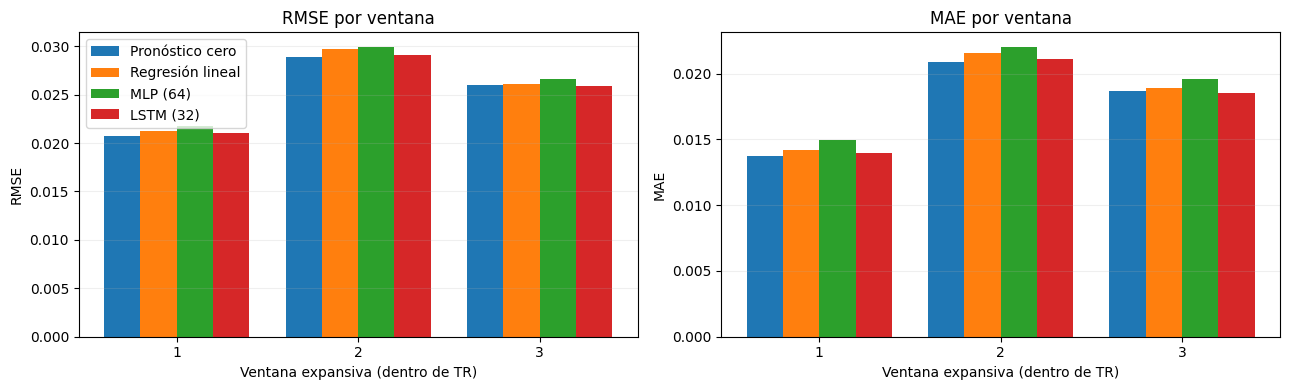

In [8]:
ORDEN = ["Pronóstico cero", "Regresión lineal", "MLP (64)", "LSTM (32)"]
tab = (res_vent.groupby(["ventana", "modelo"])
       .agg(MAE=("MAE", "mean"), MAE_desv=("MAE", "std"), RMSE=("RMSE", "mean"), RMSE_desv=("RMSE", "std"),
            dir_acc=("precision_direccional", "mean"), desv_prediccion=("desv_prediccion", "mean"),
            n_evaluacion=("n_evaluacion", "first")).reset_index())
tab["modelo"] = pd.Categorical(tab["modelo"], ORDEN, ordered=True)
tab = tab.sort_values(["ventana", "modelo"]).reset_index(drop=True)
cero = tab[tab.modelo == "Pronóstico cero"].set_index("ventana")["RMSE"]
tab["RMSE_vs_cero_%"] = [100 * (r.RMSE / cero[r.ventana] - 1) for r in tab.itertuples()]
display(tab.round(6))
tab.to_csv(SALIDA / "errores_por_ventana.csv", index=False)

resumen_vent = (tab.groupby("modelo", observed=True).agg(MAE_media=("MAE", "mean"), RMSE_media=("RMSE", "mean"), RMSE_peor=("RMSE", "max"),
        ventanas_RMSE_menor_que_cero=("RMSE_vs_cero_%", lambda s: int((s < 0).sum()))).reset_index())
display(resumen_vent.round(6))
resumen_vent.to_csv(SALIDA / "resumen_ventanas.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
anch = 0.2
for j, m in enumerate(ORDEN):
    t = tab[tab.modelo == m]
    ax[0].bar(t.ventana + (j - 1.5) * anch, t.RMSE, anch, label=m)
    ax[1].bar(t.ventana + (j - 1.5) * anch, t.MAE, anch, label=m)
for a, nm in zip(ax, ("RMSE", "MAE")):
    a.set_xticks([1, 2, 3]); a.set_xlabel("Ventana expansiva (dentro de TR)"); a.set_ylabel(nm); a.set_title(f"{nm} por ventana"); a.grid(alpha=0.2, axis="y")
ax[0].legend(); plt.tight_layout(); plt.savefig(SALIDA / "figuras" / "errores_por_ventana.png", dpi=130); plt.show()

**Lectura (calculada con los resultados de arriba)**

Indica en cuántas de las 3 ventanas cada modelo supera al pronóstico cero, cuánto cambia el error entre ventanas y cuánto varía entre semillas.

In [9]:
print("RMSE frente al pronóstico cero del MISMO bloque (%; negativo = mejora):")
piv = tab.pivot(index="ventana", columns="modelo", values="RMSE_vs_cero_%").round(2)
display(piv[["Regresión lineal", "MLP (64)", "LSTM (32)"]])
for m in ("Regresión lineal", "MLP (64)", "LSTM (32)"):
    print(f"- {m}: supera al cero en {int((piv[m] < 0).sum())} de 3 ventanas; diferencia media = {piv[m].mean():+.2f} %.")
rng = tab[tab.modelo == "Pronóstico cero"]["RMSE"]
print(f"- El RMSE del propio pronóstico cero cambia entre ventanas: de {rng.min():.4f} a {rng.max():.4f} (×{rng.max()/rng.min():.2f}). "
      "El nivel de error depende del régimen de volatilidad; por eso se compara contra la referencia del mismo bloque.")
dl = tab[tab.modelo.isin(["MLP (64)", "LSTM (32)"])]
print("- Desviación media del RMSE entre semillas:", dl.groupby("modelo", observed=True)["RMSE_desv"].mean().round(6).to_dict())

RMSE frente al pronóstico cero del MISMO bloque (%; negativo = mejora):


modelo,Regresión lineal,MLP (64),LSTM (32)
ventana,,,
1,2.15,4.57,1.37
2,2.63,3.52,0.66
3,0.33,2.49,-0.42


- Regresión lineal: supera al cero en 0 de 3 ventanas; diferencia media = +1.70 %.
- MLP (64): supera al cero en 0 de 3 ventanas; diferencia media = +3.53 %.
- LSTM (32): supera al cero en 1 de 3 ventanas; diferencia media = +0.54 %.
- El RMSE del propio pronóstico cero cambia entre ventanas: de 0.0208 a 0.0289 (×1.39). El nivel de error depende del régimen de volatilidad; por eso se compara contra la referencia del mismo bloque.
- Desviación media del RMSE entre semillas: {'MLP (64)': 0.000441, 'LSTM (32)': 0.000155}


## 6. Pronóstico de un periodo y alcance

Se mantiene el pronóstico de un periodo (obligatorio): al cierre de *t* se estima y<sub>t</sub> = P<sub>t+1</sub>/P<sub>t</sub> − 1 con los 20 rendimientos más recientes. La ampliación opcional (comparar pronóstico directo y recursivo hasta cinco periodos) no se realiza en este avance; si se hiciera, habría que evaluar el error por horizonte en VA y excluir los ejemplos cuyo objetivo cruce la frontera del conjunto.

### Diferenciación fraccionaria: propósito y pertinencia
Diferenciar una serie con orden entero (d = 1, como al pasar de precios a rendimientos) la vuelve estacionaria pero borra gran parte de su memoria. La diferenciación fraccionaria usa un orden no entero 0 < d < 1 para estabilizar la serie conservando parte de esa memoria; el orden se elige como el menor d que supere una prueba de estacionariedad, y su utilidad debe comprobarse con VA.

**Para este proyecto no es pertinente por ahora:** las entradas son rendimientos diarios (ya estacionarios en media, sin tendencia de nivel) y los indicadores del Avance 5 (distancia a la SMA, volatilidad) son razones o desviaciones acotadas. Sí podría estudiarse si se alimentara al modelo con el nivel del precio, donde diferenciar con d = 1 elimina la memoria. Su implementación es una ampliación opcional y no se realiza.

## 7. Predicciones en VA para definir la señal

Para la regla de señal se usan los modelos ya seleccionados en el Avance 2 (guardados en `salidas_capitulo8/modelos/`, entrenados en la T4 con parada temprana sobre VA): **LSTM (32)** y **MLP (64)**, semilla 42, además de la regresión lineal ajustada con TR. Aquí solo se hace inferencia: no se entrena nada nuevo ni se carga TE.
Se comprueba que las predicciones reproducen el RMSE de VA registrado en el Avance 2.

In [10]:
va = idx["VA"]
esc_tr = F.EscaladorTR(CANALES).ajustar(Xc[idx["TR"]], y_real[idx["TR"]], ej.fecha_objetivo[idx["TR"]])
F.verificar_ajuste_solo_TR(esc_tr, ej, idx)
esc_guardado = F.EscaladorTR.cargar(SAL2 / "modelos" / "escalador_tr.joblib")
assert np.allclose(esc_guardado.sx.mean_, esc_tr.sx.mean_) and np.allclose(esc_guardado.sx.scale_, esc_tr.sx.scale_) \
    and np.isclose(esc_guardado.y_mu, esc_tr.y_mu) and np.isclose(esc_guardado.y_sd, esc_tr.y_sd), "El escalador del Avance 2 no coincide."
print("✔ El escalador (solo TR) coincide con el guardado en el Avance 2.")

X_va = esc_tr.x(Xc[va]); y_va = y_real[va]
seleccion2 = pd.read_csv(SAL2 / "seleccion_configuraciones.csv").set_index("red")
preds_va = {}
for tipo in ("LSTM", "MLP"):
    ruta = SAL2 / "modelos" / f"{tipo.lower()}_neuronas{NEURONAS[tipo]}_semilla42.keras"
    if not ruta.exists():
        raise DatosError(f"No existe {ruta}. Copie salidas_capitulo8/modelos/ del Avance 2 junto a este notebook.")
    modelo = keras.models.load_model(ruta)
    p = esc_tr.y_inv(modelo(tf.convert_to_tensor(entrada_modelo(X_va, tipo), dtype=tf.float32), training=False).numpy().reshape(-1))
    rm = M.rmse(y_va, p)
    assert abs(rm - float(seleccion2.loc[tipo, "RMSE_VA"])) < 1e-5, f"{tipo}: RMSE de VA {rm:.6f} no reproduce el del Avance 2."
    preds_va[tipo] = p
lin_tr = LinearRegression().fit(esc_tr.x(Xc[idx["TR"]]).reshape(len(idx["TR"]), -1), y_real[idx["TR"]])
preds_va["Regresión lineal"] = lin_tr.predict(X_va.reshape(len(va), -1))
preds_va["Pronóstico cero"] = np.zeros(len(va))

resumen_pred = pd.DataFrame({k: {"media": p.mean(), "desv": p.std(), "min": p.min(), "max": p.max(),
                                 "RMSE_VA": M.rmse(y_va, p), "MAE_VA": M.mae(y_va, p)} for k, p in preds_va.items()}).T
display(resumen_pred.round(6))
assert all(np.isfinite(p).all() for p in preds_va.values())
print("✔ Predicciones de VA finitas y reproducidas. Desv. del rendimiento real en VA:", round(float(y_va.std()), 6))

✔ El escalador (solo TR) coincide con el guardado en el Avance 2.


,media,desv,min,max,RMSE_VA,MAE_VA
LSTM,0.000732,0.000445,-0.000491,0.002972,0.019301,0.014228
MLP,0.002223,0.004221,-0.012968,0.016133,0.019883,0.014760
Regresión lineal,0.000705,0.002348,-0.005869,0.009661,0.019683,0.014545
Pronóstico cero,0.000000,0.000000,0.000000,0.000000,0.019259,0.014210


✔ Predicciones de VA finitas y reproducidas. Desv. del rendimiento real en VA: 0.019245


## 8. Umbrales candidatos y regla de señal

**Regla:** al cierre de *t*, si el rendimiento estimado supera δ, se emite señal de comprar (100 % del capital en el activo); en otro caso, efectivo (sin ventas en corto). La señal emitida al cierre de *t* se ejecuta en la apertura de *t+1*; el patrimonio se valora al cierre.

**Costo académico:** 0.10 % por compra y por venta sobre el monto negociado, solo cuando cambia la posición (no se recompra a diario); la compra incluye el costo al calcular cuánto se adquiere.

**Capital inicial:** 100,000 USD. Al final se liquida la posición al último cierre (con costo) para comparar con *efectivo* y *comprar y mantener* en la misma fecha.

**Umbrales candidatos (fijados antes de calcular, positivos, máximo cinco):** δ ∈ {0.05 %, 0.10 %, 0.15 %, 0.20 %, 0.30 %}.

**Criterio (fijado de antemano):** mayor rendimiento neto en VA; en empate, menor drawdown; si persiste, el δ más bajo.

**Modelo de la señal:** la red con menor RMSE de VA del Avance 2. El resto se muestra solo como sensibilidad. *Un umbral no equivale a una probabilidad de acierto.*

In [11]:
UMBRALES = [0.0005, 0.0010, 0.0015, 0.0020, 0.0030]
CAPITAL, COSTO = 100_000.0, 0.001
dd = d.set_index("fecha")
fe = ej.fecha_objetivo[va]                       # fecha de ejecución = día t+1
assert (fe > ej.fecha_emision[va]).all()
op_va, cl_va = dd.loc[fe, "open"].to_numpy(), dd.loc[fe, "close"].to_numpy()
kw = dict(capital=CAPITAL, costo=COSTO)

modelo_senal = min(("LSTM", "MLP"), key=lambda k: M.rmse(y_va, preds_va[k]))
print("Modelo de la señal (menor RMSE de VA entre las redes):", modelo_senal)

tab_umbral = V.evaluar_umbrales(preds_va[modelo_senal], fe, op_va, cl_va, UMBRALES, **kw)
tab_umbral.insert(0, "modelo_senal", modelo_senal)
display(tab_umbral.round(5))
elegido = V.elegir_umbral(tab_umbral)
DELTA = float(elegido["umbral"])
print(f"\n→ Regla seleccionada en VA: comprar si el rendimiento estimado > {DELTA:.4%} (modelo {modelo_senal}); en otro caso, efectivo.")
tab_umbral.to_csv(SALIDA / "umbrales_probados_VA.csv", index=False)

# Referencias en las mismas fechas y con costos equivalentes
_, ref_cash = V.simular(fe, op_va, cl_va, np.zeros(len(va), bool), **kw)
_, ref_bh = V.simular(fe, op_va, cl_va, np.ones(len(va), bool), **kw)
comp = pd.DataFrame({"Efectivo": ref_cash, "Comprar y mantener": ref_bh, f"Regla {modelo_senal} (δ={DELTA:.2%})": elegido[list(ref_cash.keys())].to_dict()}).T
display(comp[["rendimiento_neto", "max_drawdown", "n_operaciones_cerradas", "win_rate", "costos_totales", "patrimonio_final"]].round(4))
comp.to_csv(SALIDA / "comparacion_regla_vs_referencias_VA.csv")

# Sensibilidad (informativa; la regla elegida es la de arriba)
sens = []
for k in ("LSTM", "MLP", "Regresión lineal"):
    t = V.evaluar_umbrales(preds_va[k], fe, op_va, cl_va, UMBRALES, **kw); t.insert(0, "modelo_senal", k); sens.append(t)
sens = pd.concat(sens, ignore_index=True)
display(sens[["modelo_senal", "umbral", "senales_compra", "rendimiento_neto", "max_drawdown", "n_operaciones_cerradas", "win_rate"]].round(4))
sens.to_csv(SALIDA / "sensibilidad_umbrales_VA.csv", index=False)

Modelo de la señal (menor RMSE de VA entre las redes): LSTM


,modelo_senal,umbral,senales_compra,patrimonio_final,rendimiento_neto,max_drawdown,n_compras,n_ventas,n_operaciones_cerradas,win_rate,costos_totales,dias_en_posicion
0,LSTM,0.0005,198,83377.74427,-0.16622,0.33062,44,44,44,0.38636,9652.28191,198
1,LSTM,0.0010,50,93826.49819,-0.06174,0.21244,21,21,21,0.66667,4476.05601,50
2,LSTM,0.0015,16,92641.15155,-0.07359,0.15867,7,7,7,0.42857,1435.95184,16
3,LSTM,0.0020,6,100998.53073,0.00999,0.02361,3,3,3,0.66667,605.23098,6
4,LSTM,0.0030,0,100000.00000,0.00000,0.00000,0,0,0,NaN,0.00000,0



→ Regla seleccionada en VA: comprar si el rendimiento estimado > 0.2000% (modelo LSTM); en otro caso, efectivo.


,rendimiento_neto,max_drawdown,n_operaciones_cerradas,win_rate,costos_totales,patrimonio_final
Efectivo,0.0000,0.0000,0.0,NaN,0.0000,100000.0000
Comprar y mantener,-0.2221,0.3943,1.0,0.0000,177.7674,77789.4722
Regla LSTM (δ=0.20%),0.0100,0.0236,3.0,0.6667,605.2310,100998.5307


,modelo_senal,umbral,senales_compra,rendimiento_neto,max_drawdown,n_operaciones_cerradas,win_rate
0,LSTM,0.0005,198,-0.1662,0.3306,44,0.3864
1,LSTM,0.0010,50,-0.0617,0.2124,21,0.6667
2,LSTM,0.0015,16,-0.0736,0.1587,7,0.4286
3,LSTM,0.0020,6,0.0100,0.0236,3,0.6667
4,LSTM,0.0030,0,0.0000,0.0000,0,NaN
5,MLP,0.0005,182,-0.2214,0.3423,61,0.4918
6,MLP,0.0010,168,-0.0910,0.2998,65,0.5231
7,MLP,0.0015,157,-0.0976,0.3073,68,0.5588
8,MLP,0.0020,145,-0.1482,0.3141,68,0.5294
9,MLP,0.0030,110,-0.2469,0.3049,66,0.4697


### Simulación de la regla seleccionada en VA (diagnóstico)

,fecha,fecha_emision,precio_ejecucion,precio_cierre,senal,posicion_unidades,efectivo,costo_dia,costos_acumulados,patrimonio,pred_rendimiento
0,2025-05-08,2025-05-07,97034.250000,103241.460938,0,0.0,100000.0,0.0,0.0,100000.0,0.000738
1,2025-05-09,2025-05-08,103239.125000,102970.851562,0,0.0,100000.0,0.0,0.0,100000.0,0.000395
2,2025-05-10,2025-05-09,102973.710938,104696.328125,0,0.0,100000.0,0.0,0.0,100000.0,0.001042
3,2025-05-11,2025-05-10,104701.070312,104106.359375,0,0.0,100000.0,0.0,0.0,100000.0,0.001192
4,2025-05-12,2025-05-11,104106.960938,102812.953125,0,0.0,100000.0,0.0,0.0,100000.0,0.001042
5,2025-05-13,2025-05-12,102812.492188,104169.812500,0,0.0,100000.0,0.0,0.0,100000.0,0.000608
6,2025-05-14,2025-05-13,104167.328125,103539.414062,0,0.0,100000.0,0.0,0.0,100000.0,0.000838
7,2025-05-15,2025-05-14,103538.828125,103744.640625,0,0.0,100000.0,0.0,0.0,100000.0,0.000628


{'patrimonio_final': 100998.53073171624, 'rendimiento_neto': 0.009985307317162295, 'max_drawdown': 0.02360737456396883, 'n_compras': 3, 'n_ventas': 3, 'n_operaciones_cerradas': 3, 'win_rate': 0.6666666666666666, 'costos_totales': 605.2309764617826, 'dias_en_posicion': 6}


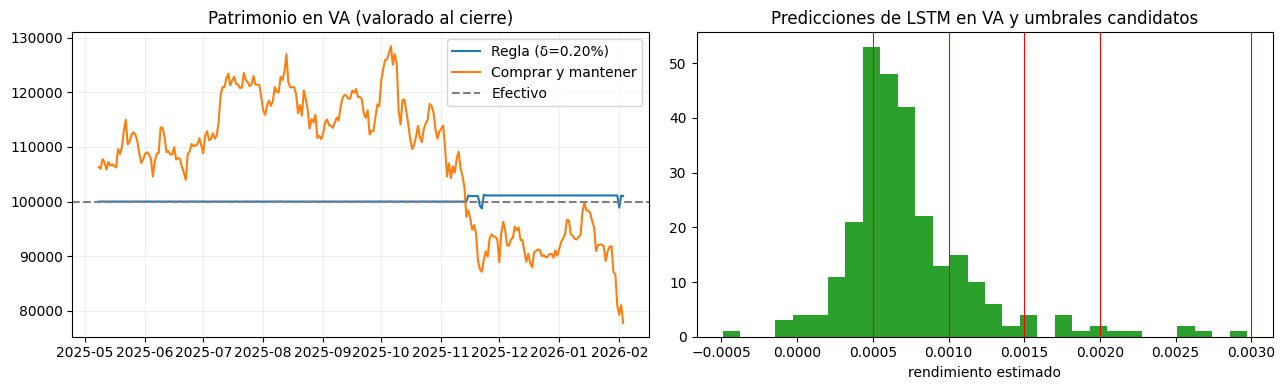

In [12]:
sim, res_sim = V.simular(fe, op_va, cl_va, preds_va[modelo_senal] > DELTA, **kw)
sim.insert(1, "fecha_emision", ej.fecha_emision[va].values)
sim["pred_rendimiento"] = preds_va[modelo_senal]
sim.to_csv(SALIDA / "simulacion_VA_regla_seleccionada.csv", index=False)
display(sim.head(8)); print(res_sim)

sim_bh, _ = V.simular(fe, op_va, cl_va, np.ones(len(va), bool), **kw)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(sim.fecha, sim.patrimonio, label=f"Regla (δ={DELTA:.2%})"); ax[0].plot(sim_bh.fecha, sim_bh.patrimonio, label="Comprar y mantener")
ax[0].axhline(CAPITAL, color="gray", ls="--", label="Efectivo"); ax[0].set_title("Patrimonio en VA (valorado al cierre)"); ax[0].legend(); ax[0].grid(alpha=0.2)
ax[1].hist(preds_va[modelo_senal], bins=30, color="C2")
for u in UMBRALES:
    ax[1].axvline(u, color="r", lw=0.8)
ax[1].set_title(f"Predicciones de {modelo_senal} en VA y umbrales candidatos"); ax[1].set_xlabel("rendimiento estimado")
plt.tight_layout(); plt.savefig(SALIDA / "figuras" / "regla_seleccionada_VA.png", dpi=130); plt.show()

### ¿El resultado depende de un único periodo favorable?
Se repite la regla elegida en tres tramos consecutivos de VA (capital reiniciado en cada uno) frente a comprar y mantener.

In [13]:
tramos = np.array_split(np.arange(len(va)), 3)
filas = []
for k, t in enumerate(tramos, 1):
    _, r_reg = V.simular(fe[t], op_va[t], cl_va[t], preds_va[modelo_senal][t] > DELTA, **kw)
    _, r_bh = V.simular(fe[t], op_va[t], cl_va[t], np.ones(len(t), bool), **kw)
    filas.append({"tramo_VA": k, "desde": fe[t].min().date(), "hasta": fe[t].max().date(),
                  "rend_regla": r_reg["rendimiento_neto"], "rend_comprar_mantener": r_bh["rendimiento_neto"],
                  "operaciones_regla": r_reg["n_operaciones_cerradas"], "max_dd_regla": r_reg["max_drawdown"]})
tramos_df = pd.DataFrame(filas); display(tramos_df.round(4)); tramos_df.to_csv(SALIDA / "robustez_tramos_VA.csv", index=False)

,tramo_VA,desde,hasta,rend_regla,rend_comprar_mantener,operaciones_regla,max_dd_regla
0,1,2025-05-08,2025-08-06,0.00,0.1831,0,0.0000
1,2,2025-08-07,2025-11-05,0.00,-0.0986,0,0.0000
2,3,2025-11-06,2026-02-03,0.01,-0.2735,3,0.0236


## 9. Controles antes de continuar

Se verifican de forma automática las reglas del avance: tres ventanas expansivas dentro de TR, entrenamientos anteriores a su bloque, escaladores ajustados solo con cada entrenamiento, métricas y predicciones finitas, umbrales fijados antes, ejecución en t+1, costo y capital, checkpoints guardados, uso de la GPU T4 y TE sin usar. Si algún control falla, el notebook se detiene y no se debe pasar al Avance 4.

In [14]:
usados = set(map(int, va))
for v in ventanas:
    usados |= set(map(int, v.idx_train)) | set(map(int, v.idx_eval))
te = set(map(int, idx["TE"]))
controles = [
    ("Se hicieron tres ventanas expansivas dentro de TR", bool(len(ventanas) == 3)),
    ("Cada entrenamiento termina antes del bloque que evalúa",
     bool(all(ej.fecha_objetivo[v.idx_train].max() < ej.fecha_emision[v.idx_eval].min() for v in ventanas))),
    ("Entrenamientos y bloques evaluados están dentro de TR",
     bool(all(set(map(int, v.idx_train)) | set(map(int, v.idx_eval)) <= set(map(int, idx["TR"])) for v in ventanas))),
    ("Escaladores reajustados solo con el entrenamiento de cada ventana", bool(len(ESC_OK) == 3 and all(ESC_OK))),
    ("Entradas MLP (n, 20) y LSTM (n, 20, 1)", bool(entrada_modelo(Xc[:2], "MLP").shape[1] == 20 and Xc[:2].shape[1:] == (20, 1))),
    ("Métricas por ventana finitas", bool(np.isfinite(res_vent[["MAE", "RMSE"]].to_numpy()).all())),
    ("Predicciones de VA finitas", bool(all(np.isfinite(p).all() for p in preds_va.values()))),
    ("Hasta cinco umbrales, todos positivos y fijados antes", bool(len(UMBRALES) <= 5 and all(u > 0 for u in UMBRALES))),
    ("Umbral y modelo de señal elegidos solo con VA", bool(set(map(int, va)) <= usados)),
    ("Ejecución en t+1 posterior a la emisión", bool((fe > ej.fecha_emision[va]).all())),
    ("Costo 0.10 % y capital 100,000", bool(COSTO == 0.001 and CAPITAL == 100_000)),
    ("TE no intervino en ninguna decisión", bool(usados.isdisjoint(te))),
    ("Todas las corridas profundas calcularon en GPU",
     bool(len(EVIDENCIA_GPU) == 3 * 2 * len(SEMILLAS) and all("GPU" in e["dispositivo_salida_modelo"].upper() for e in EVIDENCIA_GPU.values()))),
    ("Se guardó un checkpoint por cada corrida profunda de las ventanas", bool(len(list(CK_VENT.glob("*.keras"))) == 3 * 2 * len(SEMILLAS))),
    ("GPU T4 identificada y operación GPU verificada", bool("T4" in smi.stdout.upper() or any("T4" in n.upper() for n in gpu_names))),
]
tabla_controles = pd.DataFrame(controles, columns=["control", "cumple"]); display(tabla_controles)
assert tabla_controles.cumple.all(), "Uno o más controles fallaron: no continúe al Avance 4 hasta resolverlo."
tabla_controles.to_csv(SALIDA / "controles_finales.csv", index=False)

,control,cumple
0,Se hicieron tres ventanas expansivas dentro de TR,True
1,Cada entrenamiento termina antes del bloque qu...,True
2,Entrenamientos y bloques evaluados están dentr...,True
3,Escaladores reajustados solo con el entrenamie...,True
4,"Entradas MLP (n, 20) y LSTM (n, 20, 1)",True
5,Métricas por ventana finitas,True
6,Predicciones de VA finitas,True
7,"Hasta cinco umbrales, todos positivos y fijado...",True
8,Umbral y modelo de señal elegidos solo con VA,True
9,Ejecución en t+1 posterior a la emisión,True


## 10. Registro de ejecución y bitácora

Se guardan los datos para reproducir el avance: versiones de Python y librerías, GPU T4, semillas, hiperparámetros, ventanas, umbrales, regla seleccionada, costo y capital, y la evidencia de GPU de cada corrida. También se registra en la bitácora que no hubo incidentes en la validación temporal.

In [15]:
bit.registrar("validación temporal", "sin incidentes en las tres ventanas expansivas",
              "los entrenamientos terminan antes de cada bloque evaluado y las transformaciones se ajustaron solo con su entrenamiento",
              "ninguna: se verificó con FugaError y controles finales", "controles finales aprobados; TE no utilizado")
bit.guardar(SALIDA / "bitacora_avance3.csv")

registro = {
    "activo": ficha.get("ticker", "BTC-USD"),
    "fecha_ejecucion_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "python": platform.python_version(), "tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "gpu_tensorflow": gpu_names, "nvidia_smi": smi.stdout,
    "ventana_entrada": VENTANA, "canales": list(CANALES),
    "particiones": {k: int(len(x)) for k, x in idx.items()},
    "ventanas_expansivas": tabla_vent.astype(str).to_dict(orient="records"),
    "neuronas": NEURONAS, "semillas": SEMILLAS, "max_epocas": MAX_EPOCAS, "lote": LOTE, "tasa_aprendizaje": TASA, "paciencia": PACIENCIA,
    "umbrales_candidatos": UMBRALES, "criterio_umbral": "mayor rendimiento neto en VA; empate: menor drawdown; luego menor delta",
    "modelo_senal": modelo_senal, "umbral_seleccionado": DELTA,
    "capital_inicial": CAPITAL, "costo_por_operacion": COSTO, "ejecucion": "apertura de t+1 (senal emitida al cierre de t)",
    "evidencia_gpu_durante_entrenamiento": EVIDENCIA_GPU,
}
(SALIDA / "registro_avance3.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
regla = {"modelo_senal": modelo_senal, "umbral": DELTA, "regla": f"comprar si rendimiento estimado > {DELTA}; en otro caso efectivo",
         "seleccionada_con": "VA", "TE_utilizado": False,
         **{k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in elegido.items() if k != "modelo_senal"}}
(SALIDA / "regla_seleccionada.json").write_text(json.dumps(regla, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Archivos generados en", SALIDA, ":", sorted(p.name for p in SALIDA.iterdir() if p.is_file()))

Archivos generados en /content/drive/MyDrive/Material/salidas_capitulo9 : ['bitacora_avance3.csv', 'comparacion_regla_vs_referencias_VA.csv', 'controles_finales.csv', 'errores_por_ventana.csv', 'errores_por_ventana_corridas.csv', 'evidencia_gpu_ventanas.csv', 'registro_avance3.json', 'regla_seleccionada.json', 'resumen_ventanas.csv', 'robustez_tramos_VA.csv', 'sensibilidad_umbrales_VA.csv', 'simulacion_VA_regla_seleccionada.csv', 'tabla_ventanas_expansivas.csv', 'umbrales_probados_VA.csv']


## 11. Reflexión del avance

Se resume lo aprendido con cifras calculadas de las salidas anteriores: si los modelos superan al pronóstico cero en las distintas ventanas, si la regla elegida depende de un solo periodo, cuántas operaciones la respaldan y cómo se comparan sus resultados con efectivo y comprar y mantener. Cierra aclarando los límites de la evidencia y que TE sigue sin usarse.

In [16]:
gl = resumen_vent.set_index("modelo")
print("1) ¿El resultado depende de un único periodo favorable?")
print(f"   - Ventanas en que cada modelo supera al cero en RMSE (de 3): lineal={int(gl.loc['Regresión lineal','ventanas_RMSE_menor_que_cero'])}, "
      f"MLP={int(gl.loc['MLP (64)','ventanas_RMSE_menor_que_cero'])}, LSTM={int(gl.loc['LSTM (32)','ventanas_RMSE_menor_que_cero'])}.")
print(f"   - Regla en VA por tramos: rendimiento de la regla = {tramos_df.rend_regla.round(4).tolist()} vs. comprar y mantener = {tramos_df.rend_comprar_mantener.round(4).tolist()}.")
print("2) Regla seleccionada:", f"{modelo_senal}, δ = {DELTA:.2%}, rendimiento neto en VA = {elegido['rendimiento_neto']:.2%}, "
      f"drawdown = {elegido['max_drawdown']:.2%}, operaciones cerradas = {int(elegido['n_operaciones_cerradas'])}.")
print(f"   Referencias en VA: efectivo = {ref_cash['rendimiento_neto']:.2%}, comprar y mantener = {ref_bh['rendimiento_neto']:.2%}.")
print(f"3) Dispersión de las predicciones de {modelo_senal} en VA: desv. = {preds_va[modelo_senal].std():.6f} (real: {y_va.std():.6f}); "
      f"señales de compra con el δ elegido: {int((preds_va[modelo_senal] > DELTA).sum())} de {len(va)} días.")
print("4) TE no se utilizó. Antes de abrirlo (Avance 5) se congelará la configuración final.")
n_sen = int((preds_va[modelo_senal] > DELTA).sum())
print(f"5) Límite de la evidencia: la regla elegida se apoya en {n_sen} días de compra y {int(elegido['n_operaciones_cerradas'])} operaciones cerradas "
      f"({n_sen / len(va):.1%} de VA) y toda su ganancia ocurre en el tramo {int(tramos_df.loc[tramos_df.rend_regla.abs().idxmax(), 'tramo_VA'])} de 3. "
      "Es un resultado muestral de un solo periodo: no demuestra que la regla funcione en general. "
      "Con δ menores la misma red pierde dinero y los otros modelos pierden en todos los umbrales (ver sensibilidad_umbrales_VA.csv).")

1) ¿El resultado depende de un único periodo favorable?
   - Ventanas en que cada modelo supera al cero en RMSE (de 3): lineal=0, MLP=0, LSTM=1.
   - Regla en VA por tramos: rendimiento de la regla = [0.0, 0.0, 0.01] vs. comprar y mantener = [0.1831, -0.0986, -0.2735].
2) Regla seleccionada: LSTM, δ = 0.20%, rendimiento neto en VA = 1.00%, drawdown = 2.36%, operaciones cerradas = 3.
   Referencias en VA: efectivo = 0.00%, comprar y mantener = -22.21%.
3) Dispersión de las predicciones de LSTM en VA: desv. = 0.000445 (real: 0.019245); señales de compra con el δ elegido: 6 de 272 días.
4) TE no se utilizó. Antes de abrirlo (Avance 5) se congelará la configuración final.
5) Límite de la evidencia: la regla elegida se apoya en 6 días de compra y 3 operaciones cerradas (2.2% de VA) y toda su ganancia ocurre en el tramo 3 de 3. Es un resultado muestral de un solo periodo: no demuestra que la regla funcione en general. Con δ menores la misma red pierde dinero y los otros modelos pierden en to

## 12. Conclusión

* **Validación temporal.** Se hicieron tres evaluaciones con ventana expansiva dentro de TR. Cada entrenamiento termina antes del bloque que evalúa, los escaladores se reajustan solo con ese entrenamiento y TE no se usó. Las 18 corridas profundas se ejecutaron en la GPU T4 y cada una dejó su checkpoint guardado.
* **Los modelos no superan de forma estable al pronóstico cero.** Frente al cero del mismo bloque, la regresión lineal y el MLP no lo superan en ninguna de las 3 ventanas, y el LSTM lo supera solo en una (−0.4 %). En el RMSE medio el cero queda en 0.02524, el LSTM en 0.02536, la regresión lineal en 0.02567 y el MLP en 0.02611. Las diferencias son del orden de 1 %, que no es una mejora práctica. Esto es coherente con que los rendimientos diarios de BTC tienen muy poca señal predecible a partir de sus propios rezagos.
* **El error depende del régimen.** El RMSE del pronóstico cero cambia entre ventanas, de 0.0208 a 0.0289. Por eso los modelos se comparan contra el cero del mismo bloque y no entre ventanas. La variación entre semillas es pequeña en el LSTM y mayor en el MLP.
* **La regla de señal.** Se probaron cinco umbrales con el LSTM y se eligió δ = 0.20 % con el criterio fijado de antemano. En VA da +1.00 % neto, con drawdown de 2.36 % y 3 operaciones. Efectivo da 0 % y comprar y mantener da −22.2 %. Con δ más bajos la misma red pierde: −16.6 % con 0.05 %, −6.2 % con 0.10 % y −7.4 % con 0.15 %. Con δ = 0.30 % no emite señales. El MLP y la regresión lineal pierden en todos los umbrales.
* **Límites de la evidencia.** La regla se apoya en solo 6 días de compra (2.2 % de VA) y 3 operaciones, y toda su ganancia ocurre en uno de los tres tramos de VA, el último. Las predicciones del LSTM son muy poco dispersas (desviación 0.00045 frente a 0.0192 del rendimiento real), así que casi nunca supera el umbral. Su mejor resultado es sobre todo que se mantuvo en efectivo mientras el mercado caía, y no que haya predicho bien. Es un resultado muestral que no demuestra que la regla funcione en general.

* **Alcance y siguiente paso.** No se implementaron el pronóstico de varios periodos ni la diferenciación fraccionaria, que son opcionales; esta última solo se explicó. La configuración se congelará antes de abrir TE en el Avance 5, y el siguiente paso es el Avance 4 (entorno de decisión).